# Assignment 2: Decision Tree Classification using the Wine Dataset
**Course**: Machine Learning  
**Dataset**: Wine Dataset (`sklearn.datasets.load_wine`)  
**Splitting Criterion**: Entropy (Information Gain)  

---
### **Tasks Overview**
1. **Load** the Wine dataset using `load_wine()` from `sklearn.datasets`.
2. **Display** feature names, target names, and the first 5 samples.
3. **Separate** into input features ($X$) and target ($y$).
4. **Split** into 80% training and 20% testing sets using `train_test_split()`.
5. **Build** a Decision Tree Classifier using **Entropy** as the criterion.
6. **Train** the model with the training data.
7. **Predict** class labels for the test dataset.
8. **Evaluate** model using **Accuracy** and **Confusion Matrix**.
9. **Visualize** the decision tree using `plot_tree()`.
10. **Identify** the root node feature and explain its importance.

## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# Set visual style
sns.set_theme(style="whitegrid")

## 2. Load the Wine Dataset & Display Details
- Load dataset using `load_wine(as_frame=True)`
- Display feature names, target class names, and first five samples

In [2]:
# Load the Wine dataset
wine = load_wine(as_frame=True)

print("=== Feature Names ===")
print(wine.feature_names)

print("\n=== Target Names (Classes) ===")
print(wine.target_names)

print("\n=== First 5 Samples of Features (X) ===")
display(wine.data.head())

print("\n=== First 5 Samples of Target (y) ===")
display(wine.target.head())

=== Feature Names ===
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

=== Target Names (Classes) ===
['class_0' 'class_1' 'class_2']

=== First 5 Samples of Features (X) ===


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



=== First 5 Samples of Target (y) ===


,target
0,0
1,0
2,0
3,0
4,0


## 3. Separate Input Features (X) and Target (y)

In [3]:
# Input features (X) and Target (y)
X = wine.data
y = wine.target

print(f"Shape of Features (X): {X.shape}")
print(f"Shape of Target (y):   {y.shape}")

Shape of Features (X): (178, 13)
Shape of Target (y):   (178,)


## 4. Split the Dataset into 80% Training and 20% Testing Data

In [4]:
# Split dataset: 80% train, 20% test (random_state=42 for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set samples: {X_train.shape[0]}")
print(f"Testing set samples:  {X_test.shape[0]}")

Training set samples: 142
Testing set samples:  36


## 5 & 6. Build and Train Decision Tree Classifier with Entropy Criterion
- Set `criterion='entropy'` to split based on Information Gain.

In [5]:
# 5. Build Decision Tree Classifier using Entropy
model = DecisionTreeClassifier(criterion='entropy', random_state=42)

# 6. Train the model
model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")
print(f"Tree Depth: {model.get_depth()}")
print(f"Number of Leaves: {model.get_n_leaves()}")

Decision Tree Model Trained Successfully!
Tree Depth: 4
Number of Leaves: 8


## 7 & 8. Predict Class Labels & Evaluate Model Performance
- Calculate **Accuracy**
- Generate **Confusion Matrix**

=== Model Evaluation ===
Accuracy Score: 97.22%

--- Confusion Matrix ---
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]

--- Classification Report ---
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



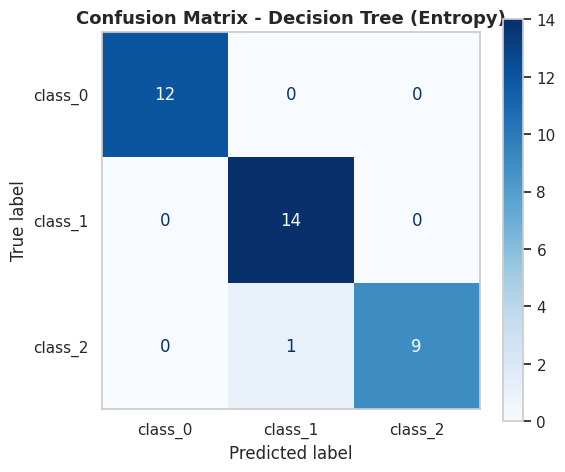

In [6]:
# 7. Predict class labels for test set
y_pred = model.predict(X_test)

# 8. Evaluate using Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"=== Model Evaluation ===")
print(f"Accuracy Score: {accuracy * 100:.2f}%")

# Evaluate using Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\n--- Confusion Matrix ---")
print(cm)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=wine.target_names))

# Plot Confusion Matrix visually
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=wine.target_names)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix - Decision Tree (Entropy)', fontsize=13, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

## 9. Visualize the Generated Decision Tree using `plot_tree()`

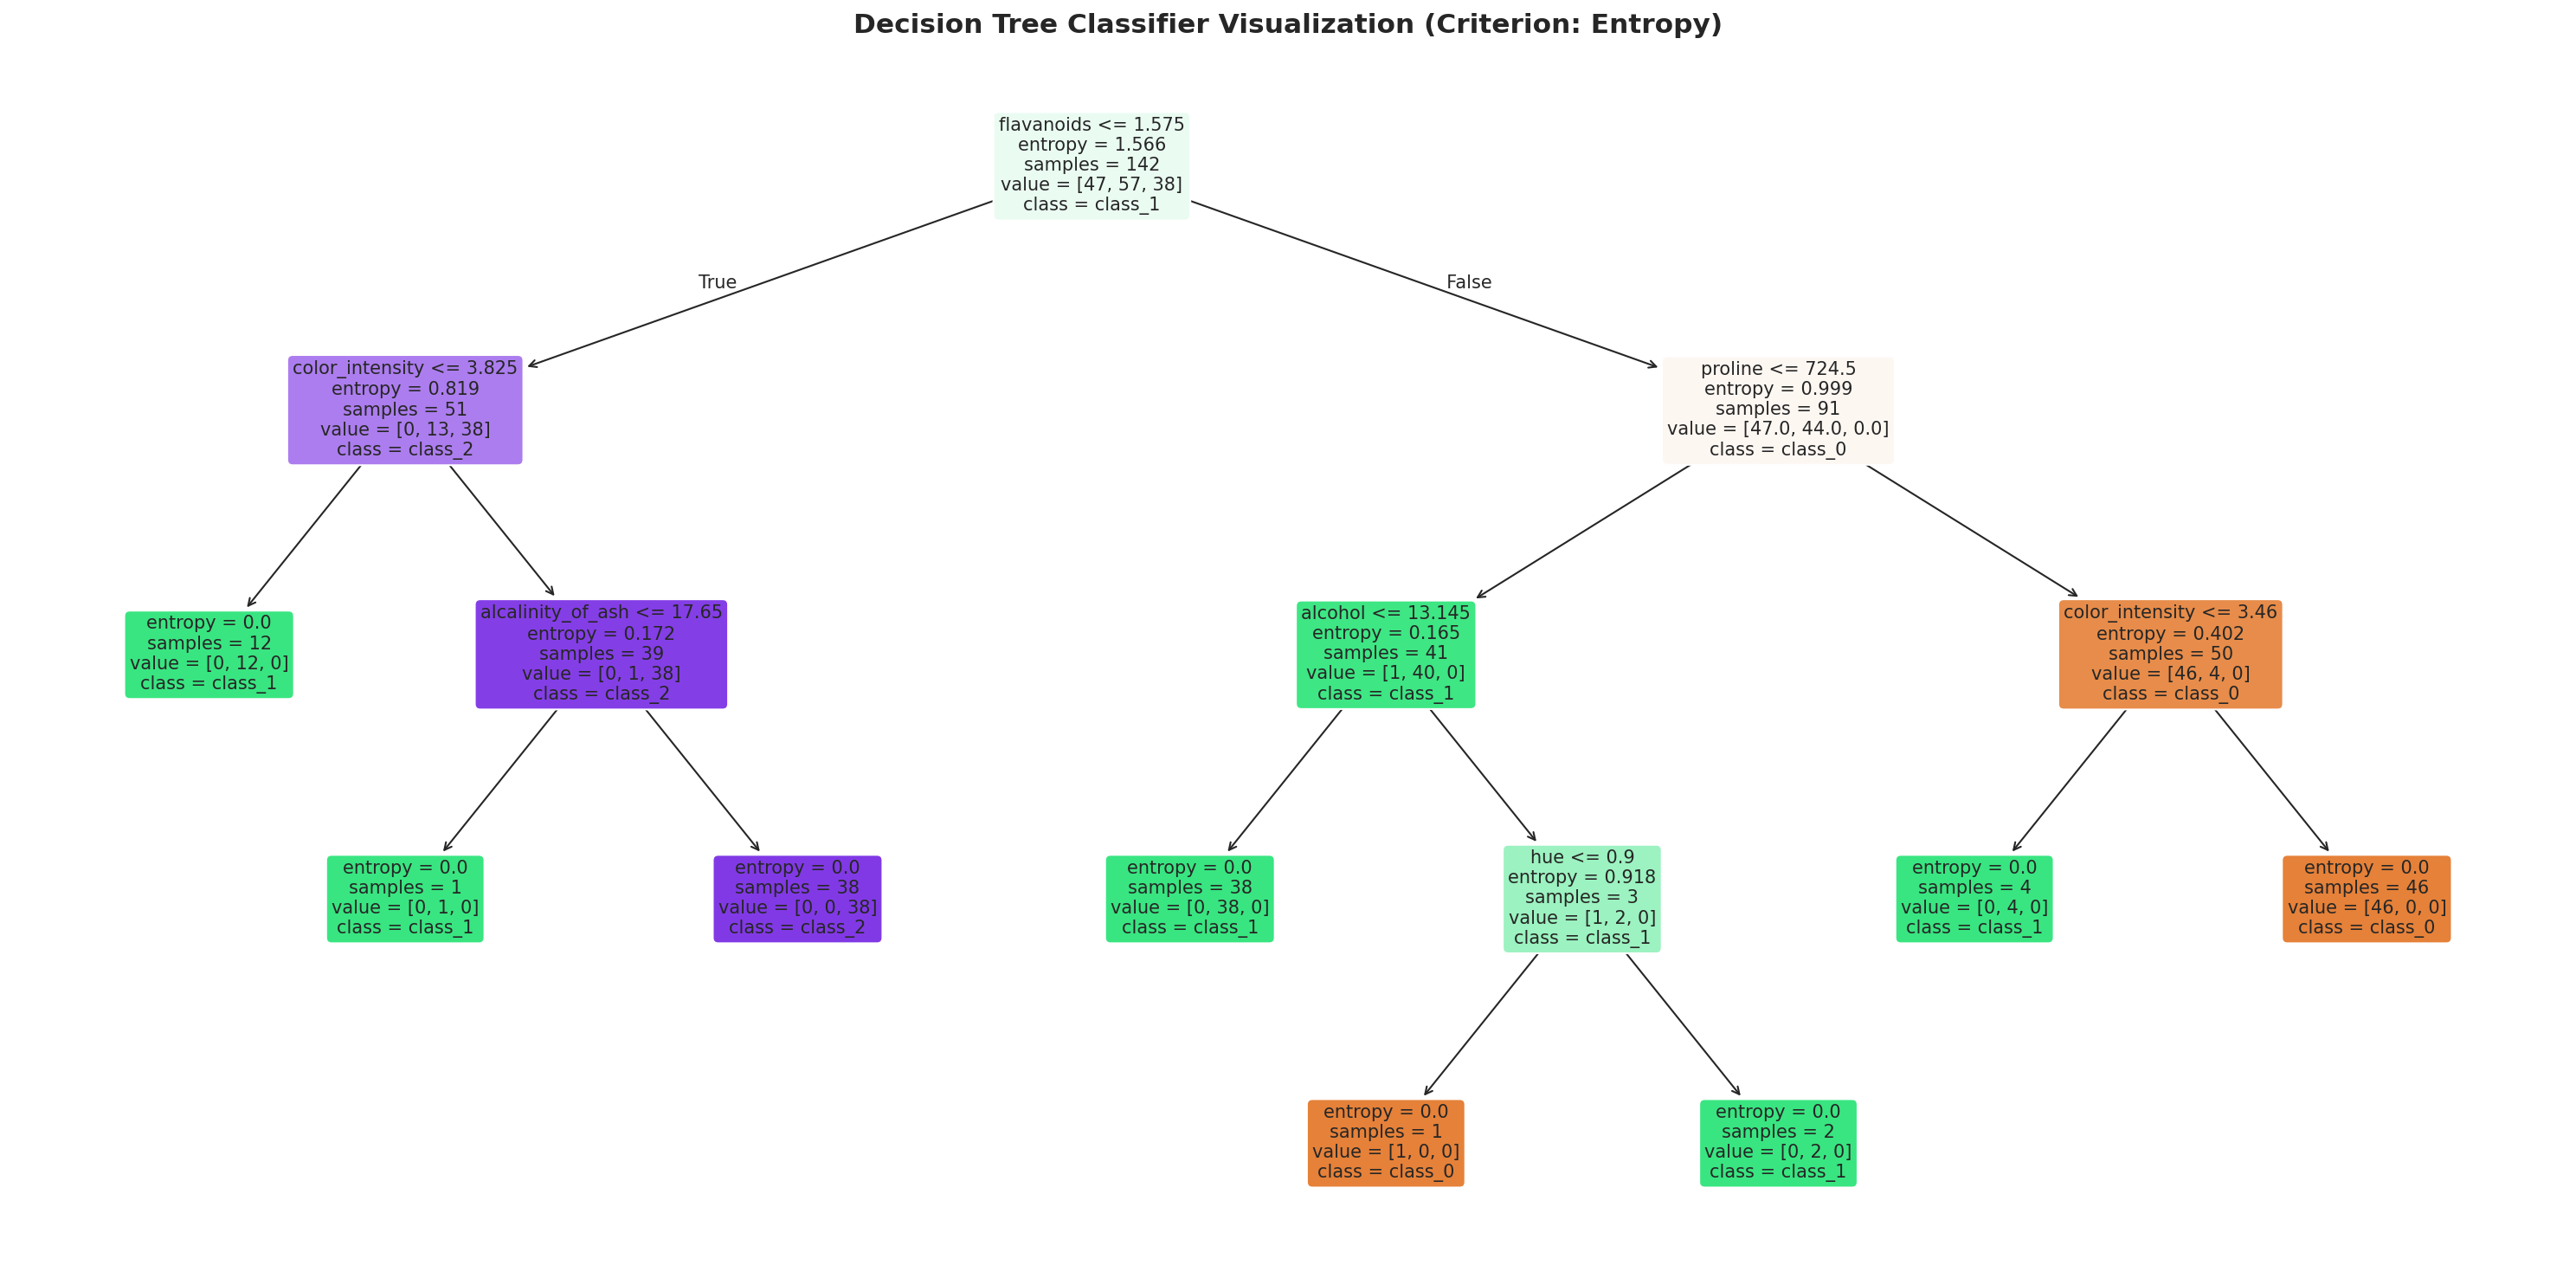

In [7]:
# 9. Visualize Decision Tree
plt.figure(figsize=(20, 10), dpi=150)
plot_tree(
    model,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Classifier Visualization (Criterion: Entropy)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Root Node Identification & Explanation

### **1. Identified Root Node Feature:**
- The feature chosen at the root node of the tree is **`flavanoids`** (with a decision split threshold at `flavanoids <= 1.575` or `1.58`).

---

### **2. Why is the Root Node Important in a Decision Tree?**
1. **Maximum Information Gain (Highest Entropy Reduction)**:
   - When building a decision tree with the `entropy` criterion, the algorithm computes the Information Gain for every available feature. The root node represents the feature that produces the **highest reduction in entropy (uncertainty)** across the complete dataset.

2. **Primary Discriminator / Splitter**:
   - The root node performs the most impactful division of the entire dataset. In the Wine dataset, the concentration of `flavanoids` provides the sharpest initial separation between wine classes (separating `class_2` from `class_0` and `class_1`).

3. **Determines Overall Tree Depth & Efficiency**:
   - Because it creates the most homogeneous initial subsets, a strong root node minimizes the overall tree depth, prevents unnecessary branch complexity, and enables faster, more accurate predictions.